In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.model_selection import ParameterGrid

In [2]:
sc=StandardScaler()
x=pd.read_csv('preprocessed.csv')
x=sc.fit_transform(x)

In [19]:
params={
    'eps':(4,5,10,15,9,11,12,13,8,7),
    'min_samples': [3, 5,7,4,6, 40]
}
best_params=None
best_score=-1
best_labels=None

In [20]:
for param in ParameterGrid(params) : 
    mod=DBSCAN(**param)
    y=mod.fit_predict(x)
    try : 
        n_cluster=len(set(y)) - (1 if -1 in y else 0)
        if n_cluster >= 2 :
            score=silhouette_score(x,y)
            if(score>best_score) : 
                best_score = score
                best_labels=y 
                best_params=param
    except Exception as e :
        pass
print(f"Best Silhouette Score: {best_score:.4f}")
print(f"Optimal Hyperparameters: {best_params}")
    

Best Silhouette Score: 0.4614
Optimal Hyperparameters: {'eps': 9, 'min_samples': 5}


In [21]:
noise_ratio= (len(set(best_labels))/len(best_labels) ) * 100 
noise_ratio

0.13537906137184114

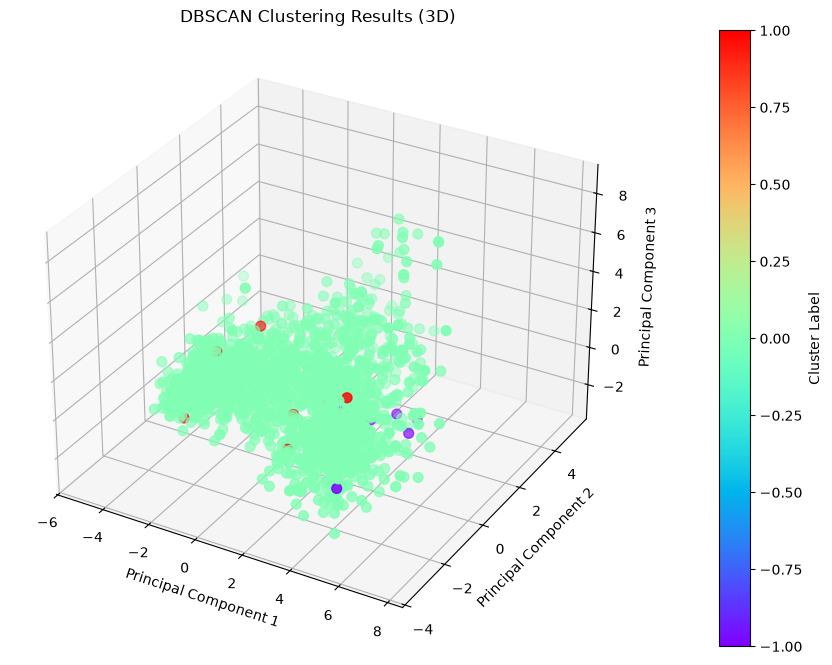

In [22]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reduce features to 3 dimensions
pca = PCA(n_components=3)
x_pca = pca.fit_transform(x)

# Create a 3D plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the clusters
scatter = ax.scatter(
    x_pca[:, 0],
    x_pca[:, 1],
    x_pca[:, 2],
    c=best_labels,
    cmap='rainbow',
    s=50
)

# Add titles and labels
ax.set_title("DBSCAN Clustering Results (3D)")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_zlabel("Principal Component 3")

# Display cluster labels
fig.colorbar(scatter, ax=ax, label="Cluster Label", pad=0.1)

plt.show()